# Loss behavior: plane wave vs FEM

See [README.md](README.md) for the writeup: FEM is not a minimizer of the
discrete Helmholtz residual used in training. A 20-30% plane-wave mix scores
lower `|r|^2` than `E_FEM` on z-crop +/-2. Uniqueness of the continuous BVP
does not apply to this operator.



In [1]:
from __future__ import annotations

from pathlib import Path
import sys

NOTEBOOK_DIR = Path(".").resolve()
if NOTEBOOK_DIR.name != "notebooks":
    candidate = NOTEBOOK_DIR / "notebooks"
    if candidate.is_dir():
        NOTEBOOK_DIR = candidate.resolve()

REPO_ROOT = NOTEBOOK_DIR.parent
for path in (NOTEBOOK_DIR, REPO_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

SAMPLE_IDS = ["sample_0000"]
THETAS_DEG = (0.0, 45.0)
PML_THICKNESS = 10
CKPT_PATH = NOTEBOOK_DIR / "latest.pt"

import torch

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"device={DEVICE}")
print(f"ckpt={CKPT_PATH} exists={CKPT_PATH.is_file()}")


device=mps
ckpt=/Users/hduva/projects/maxwellnet/notebooks/latest.pt exists=True


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset

from ckpt_io import build_fit_net, build_init_net
from maxwell_losses.helmholtz_checker import helmholtz_residual_loss_periodic_pml
from train_maxwellnet import _fft_log_intensity, _predicted_e_field, _select_gt_e_field

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "image.cmap": "magma"})
torch.set_grad_enabled(False)


torch.autograd.grad_mode.set_grad_enabled(mode=False)

## 1. Load a model only as a physics frontend

We need `eps`, `incident`, `kx`, `kz` from `PeriodicMaxwellNet.forward`.
INIT (Born head) is enough; FIT is optional for a side check that INIT already
gives `a=0`.


In [3]:
if CKPT_PATH.is_file():
    net, info = build_fit_net(CKPT_PATH, DEVICE)
    mode = info.mode
    network_specs = dict(info.network_specs)
    net_init = build_init_net(mode, network_specs, DEVICE)
    print(f"FIT epoch={info.epoch} mode={mode} specs={network_specs}")
else:
    mode = "te"
    network_specs = {"depth": 5, "filter": 32, "norm": "weight", "up_mode": "upconv"}
    net_init = build_init_net(mode, network_specs, DEVICE)
    net = net_init
    print(f"no ckpt; using INIT-only mode={mode} specs={network_specs}")

pol = "s" if mode == "te" else "p"


FIT epoch=5400 mode=te specs={'depth': 5, 'filter': 32, 'norm': 'weight', 'up_mode': 'upconv'}


/Users/hduva/projects/maxwellnet/.venv/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## 2. Load geometries


In [4]:
def decode_row(row: dict) -> dict:
    """HF row -> cropped tensors matching ShapeDataset."""
    optical = torch.complex(
        torch.as_tensor(row["optical_constant_real"]),
        torch.as_tensor(row["optical_constant_imag"]),
    )[:-1, :-1, :]
    e_field = torch.complex(
        torch.as_tensor(row["e_field_real"]),
        torch.as_tensor(row["e_field_imag"]),
    )[:-1, :-1, :]
    return {
        "sample_id": row["sample_id"],
        "optical_constant": optical,
        "e_field": e_field,
        "wavelength_nm": float(row["wavelength_nm"]),
        "pol": row["pol"],
        "theta": float(row["theta"]),
        "delta_x_a": 1.0,
        "delta_z_a": 1.0,
    }


def batchify(row: dict) -> dict:
    """Add batch dimension for PeriodicMaxwellNet."""
    out = {}
    for key, value in row.items():
        if torch.is_tensor(value):
            out[key] = value.unsqueeze(0)
        elif key in ("sample_id", "pol"):
            out[key] = [value]
        else:
            out[key] = torch.tensor([value])
    return out


ds = load_dataset(
    "als-rixs/latent-image-training",
    data_files="training/train-00000-of-00001.parquet",
    split="train",
    revision="fixed-dimension",
)

wanted_ids = set(SAMPLE_IDS)
wanted_th = set(float(t) for t in THETAS_DEG)
rows: dict[tuple[str, float], dict] = {}
for i, (sid, p, th) in enumerate(zip(ds["sample_id"], ds["pol"], ds["theta"])):
    th = float(th)
    if sid in wanted_ids and p == pol and th in wanted_th:
        key = (sid, th)
        if key not in rows:
            rows[key] = decode_row(ds[i])
            print(f"loaded {sid} theta={th:g}")

GEOM_KEYS = [(sid, float(th)) for sid in SAMPLE_IDS for th in THETAS_DEG]
missing = [k for k in GEOM_KEYS if k not in rows]
if missing:
    raise LookupError(f"missing {missing}")
batches = {k: batchify(rows[k]) for k in GEOM_KEYS}


loaded sample_0000 theta=0
loaded sample_0000 theta=45


## 3. Force fields and score

- Plane: `E=E_i` (model incident), `a=0`
- FEM + model `E_i`: `a=E_FEM/E_i-1` (what naive training bookkeeping does)
- FEM + matched `E_i`: keep `E=E_FEM`, set `E_i_matched = e^{iφ} E_i` from
  overlap so the TF/SF split sees the physical scattered field


In [5]:
def training_units(batch, kz, kx):
    """Match train_maxwellnet._compute_loss wavelength normalization."""
    wavelength_a_real = float(batch["wavelength_nm"][0]) * 10.0
    dx = float(batch["delta_x_a"][0]) / wavelength_a_real
    dz = float(batch["delta_z_a"][0]) / wavelength_a_real
    return 1.0, dx, dz, kz * wavelength_a_real, kx * wavelength_a_real


def helmholtz_of_total(e_total, eps, incident, kz, kx, batch):
    """Training Helmholtz residual for total field E with given incident."""
    wavelength_a, dx, dz, kz_n, kx_n = training_units(batch, kz, kx)
    pol_name = batch["pol"][0]
    if mode == "te":
        envelope = e_total / incident - 1.0
    else:
        envelope = e_total / incident.unsqueeze(1) - 1.0
    residual = helmholtz_residual_loss_periodic_pml(
        envelope, eps, incident, kz_n, kx_n, pol_name, wavelength_a, dx, dz, PML_THICKNESS
    )
    return residual, envelope


def analyze_geometry(key: tuple[str, float], model) -> dict:
    """Score plane wave and FEM under model vs phase-matched incident."""
    batch = batches[key]
    optical = batch["optical_constant"].to(torch.complex64).to(DEVICE)
    theta = batch["theta"].to(torch.float32).to(DEVICE)
    wl = batch["wavelength_nm"].to(torch.float32).to(DEVICE)
    dx_a = batch["delta_x_a"].to(torch.float32).to(DEVICE)
    dz_a = batch["delta_z_a"].to(torch.float32).to(DEVICE)

    env_net, eps, incident, kz, kx = model(optical, theta, wl, dx_a, dz_a)
    e_fem = _select_gt_e_field(batch["e_field"].to(DEVICE), mode)

    if mode == "te":
        overlap = (incident.conj() * e_fem).sum()
    else:
        overlap = (incident.conj() * e_fem[:, 0]).sum()
    phase = overlap / (overlap.abs() + 1e-30)
    incident_matched = incident * phase  # rotate Ei only; E_FEM unchanged

    r_plane, a_plane = helmholtz_of_total(incident, eps, incident, kz, kx, batch)
    r_fem_model, a_fem_model = helmholtz_of_total(e_fem, eps, incident, kz, kx, batch)
    r_fem_match, a_fem_match = helmholtz_of_total(e_fem, eps, incident_matched, kz, kx, batch)

    # E reconstructed with matched incident must equal E_FEM
    e_rec = incident_matched * (1.0 + a_fem_match) if mode == "te" else None
    rec_err = float((e_rec - e_fem).abs().max()) if e_rec is not None else float("nan")

    return {
        "sample_id": key[0],
        "theta": key[1],
        "sup_plane": float((incident - e_fem).abs().pow(2).mean()),
        "sup_fem": float((e_fem - e_fem).abs().pow(2).mean()),
        "hel_plane": float(r_plane.abs().pow(2).mean()),
        "hel_fem_model_Ei": float(r_fem_model.abs().pow(2).mean()),
        "hel_fem_matched_Ei": float(r_fem_match.abs().pow(2).mean()),
        "residual_plane": r_plane.detach().cpu(),
        "residual_fem_model": r_fem_model.detach().cpu(),
        "residual_fem_match": r_fem_match.detach().cpu(),
        "overlap_phase_rad": float(torch.angle(overlap)),
        "mean_abs_a_model": float(a_fem_model.abs().mean()),
        "mean_abs_a_match": float(a_fem_match.abs().mean()),
        "rec_err": rec_err,
        "incident": incident.detach().cpu(),
        "incident_matched": incident_matched.detach().cpu(),
        "e_fem": e_fem.detach().cpu(),
        "eps": eps.detach().cpu(),
        "kz": kz.detach().cpu(),
        "kx": kx.detach().cpu(),
        "mean_abs_env_net": float(env_net.abs().mean()),
    }


reports = {key: analyze_geometry(key, net_init) for key in GEOM_KEYS}
for key in GEOM_KEYS:
    assert reports[key]["rec_err"] < 1e-5
print("E_FEM unchanged under matched-Ei scoring (reconstruction error < 1e-5)")


E_FEM unchanged under matched-Ei scoring (reconstruction error < 1e-5)


## 4. Endpoints

- Supervised: plane nonzero, FEM zero.
- `hel_fem_model_Ei`: residual with ShapeNet's `E_i` (can look insane if phase conventions differ).
- `hel_fem_matched_Ei`: same `E_FEM`, incident only rotated to the FEM convention — fair discrete floor.


sample        theta   ov_deg   sup_plane    sup_FEM   hel_plane  hel_modEi hel_matchEi  |a|_mod  |a|_mt
sample_0000     0.0    178.2  3.8323e+00 0.0000e+00  3.2377e-01 1.4000e-01  1.4000e-01    1.957   0.093
sample_0000    45.0   -157.0  3.6121e+00 0.0000e+00  2.7636e-01 2.6640e+02  2.6640e+02    1.900   0.087


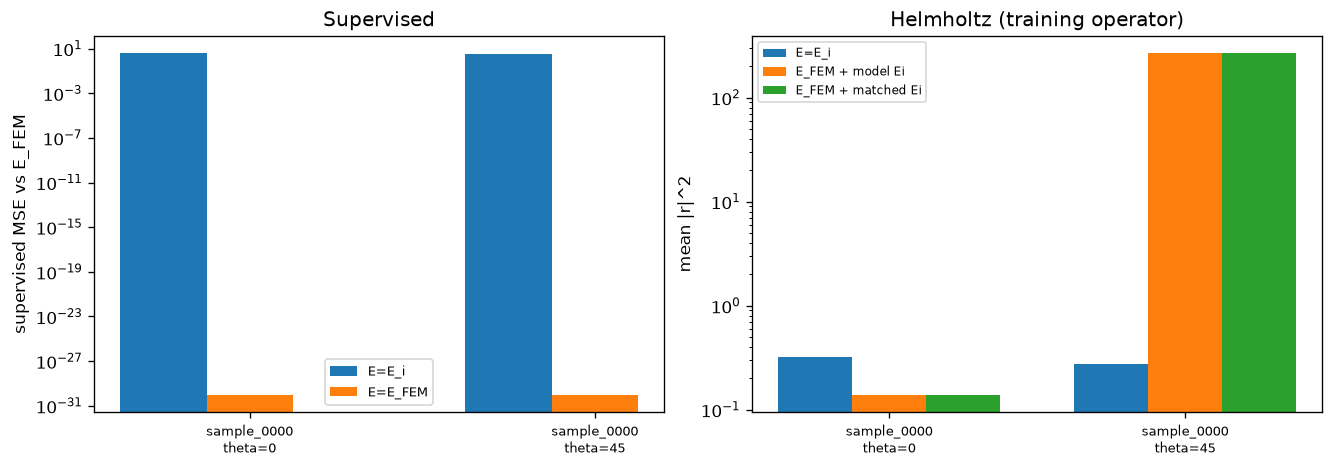

In [6]:
print(
    f"{'sample':12s} {'theta':>6s} {'ov_deg':>8s}  "
    f"{'sup_plane':>10s} {'sup_FEM':>10s}  "
    f"{'hel_plane':>10s} {'hel_modEi':>10s} {'hel_matchEi':>11s}  "
    f"{'|a|_mod':>7s} {'|a|_mt':>7s}"
)
for key in GEOM_KEYS:
    r = reports[key]
    print(
        f"{r['sample_id']:12s} {r['theta']:6.1f} {r['overlap_phase_rad']*180/np.pi:8.1f}  "
        f"{r['sup_plane']:10.4e} {r['sup_fem']:10.4e}  "
        f"{r['hel_plane']:10.4e} {r['hel_fem_model_Ei']:10.4e} {r['hel_fem_matched_Ei']:11.4e}  "
        f"{r['mean_abs_a_model']:7.3f} {r['mean_abs_a_match']:7.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
x = np.arange(len(GEOM_KEYS))
w = 0.25
labels = [f"{k[0]}\ntheta={k[1]:g}" for k in GEOM_KEYS]

axes[0].bar(x - w, [reports[k]["sup_plane"] for k in GEOM_KEYS], w, label="E=E_i")
axes[0].bar(x, [max(reports[k]["sup_fem"], 1e-30) for k in GEOM_KEYS], w, label="E=E_FEM")
axes[0].set_yscale("log")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylabel("supervised MSE vs E_FEM")
axes[0].set_title("Supervised")
axes[0].legend(fontsize=8)

axes[1].bar(x - w, [reports[k]["hel_plane"] for k in GEOM_KEYS], w, label="E=E_i")
axes[1].bar(x, [reports[k]["hel_fem_model_Ei"] for k in GEOM_KEYS], w, label="E_FEM + model Ei")
axes[1].bar(x + w, [reports[k]["hel_fem_matched_Ei"] for k in GEOM_KEYS], w, label="E_FEM + matched Ei")
axes[1].set_yscale("log")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylabel("mean |r|^2")
axes[1].set_title("Helmholtz (training operator)")
axes[1].legend(fontsize=7)
plt.show()


### Interior vs z-edge (matched-Ei FEM)

With matched incident, FEM should look good in the **interior** (it solves Helmholtz).
Edge rows still feel transparent-BC ghosts / discrete mismatch.


In [7]:
EDGE = 4

def mean_r2_region(residual: torch.Tensor, region: str) -> float:
    """Domain / interior / z-edge mean of |r|^2."""
    r2 = residual.abs().pow(2)
    if r2.ndim == 3:
        r2 = r2[0]
    elif r2.ndim == 4:
        r2 = r2[0, 0]
    if region == "all":
        return float(r2.mean())
    if region == "interior":
        return float(r2[EDGE:-EDGE].mean())
    if region == "edge":
        return float(torch.cat([r2[:EDGE].reshape(-1), r2[-EDGE:].reshape(-1)]).mean())
    raise ValueError(region)


print(
    f"{'sample':12s} {'theta':>6s}  "
    f"{'plane_in':>10s} {'fem_in':>10s}  "
    f"{'plane_edge':>10s} {'fem_edge':>10s}  "
    f"{'fem_all':>10s}"
)
for key in GEOM_KEYS:
    r = reports[key]
    rp = r["residual_plane"]
    rf = r["residual_fem_match"]
    print(
        f"{r['sample_id']:12s} {r['theta']:6.1f}  "
        f"{mean_r2_region(rp,'interior'):10.4e} {mean_r2_region(rf,'interior'):10.4e}  "
        f"{mean_r2_region(rp,'edge'):10.4e} {mean_r2_region(rf,'edge'):10.4e}  "
        f"{mean_r2_region(rf,'all'):10.4e}"
    )


sample        theta    plane_in     fem_in  plane_edge   fem_edge     fem_all
sample_0000     0.0  3.3406e-01 5.4212e-02  4.6738e-03 2.7995e+00  1.4000e-01
sample_0000    45.0  2.8524e-01 2.6099e+02  1.1896e-03 4.3406e+02  2.6640e+02


## 5. Residual maps

Plane vs FEM with **matched** incident (fair operator on the FEM Helmholtz solution).


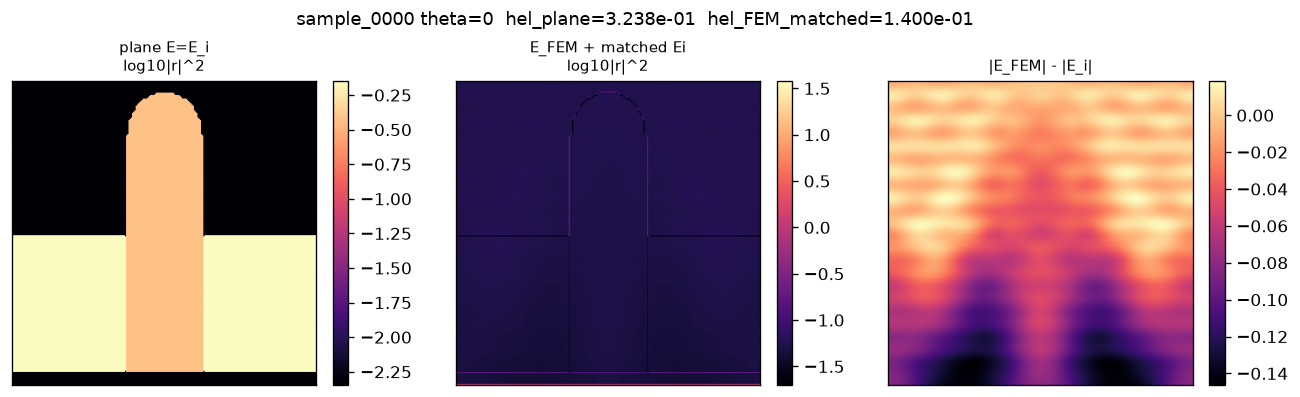

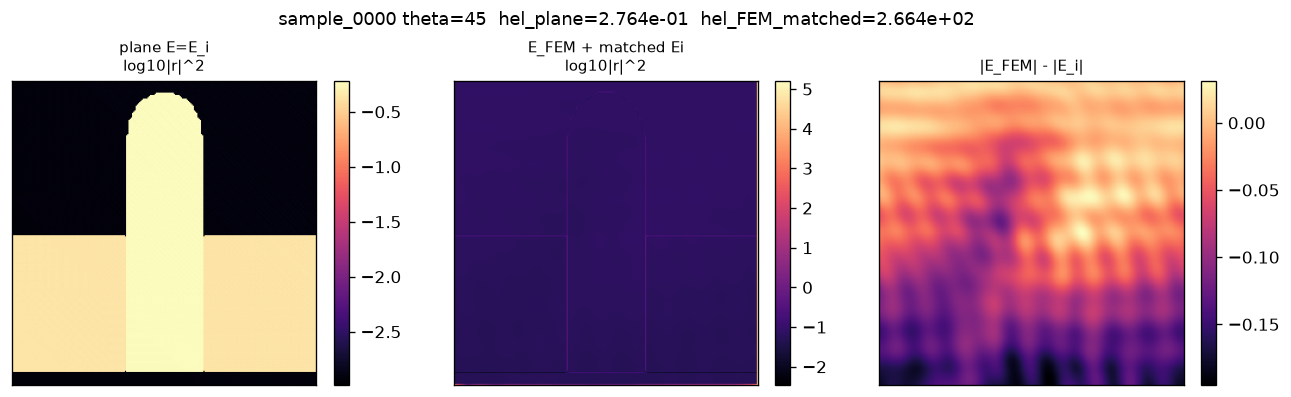

In [8]:
def log_r2(residual: torch.Tensor) -> np.ndarray:
    return torch.log10(residual.abs().pow(2) + 1e-12).numpy()


def take2d(res: torch.Tensor) -> torch.Tensor:
    if res.ndim == 3:
        return res[0]
    return res[0, 0]


for key in GEOM_KEYS:
    r = reports[key]
    rp = take2d(r["residual_plane"])
    rf = take2d(r["residual_fem_match"])
    scatter = (r["e_fem"][0].abs() - r["incident"][0].abs()).numpy() if mode == "te" else (
        r["e_fem"][0, 0].abs() - r["incident"][0].abs()
    ).numpy()

    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), constrained_layout=True)
    panels = [
        (log_r2(rp), "plane E=E_i\nlog10|r|^2"),
        (log_r2(rf), "E_FEM + matched Ei\nlog10|r|^2"),
        (scatter, "|E_FEM| - |E_i|"),
    ]
    for ax, (img, title) in zip(axes, panels):
        im = ax.imshow(img, origin="lower", aspect="equal")
        ax.set_title(title, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(
        f"{r['sample_id']} theta={r['theta']:g}  "
        f"hel_plane={r['hel_plane']:.3e}  hel_FEM_matched={r['hel_fem_matched_Ei']:.3e}",
        fontsize=11,
    )
    plt.show()


## 6. Blend debug (dense $\alpha$)

`E(α)=(1-α)E_plane + α E_FEM` with phase-matched incident.

Summary figure:
- supervised means (spatial + FFT) vs continuous $\alpha$
- Helmholtz loss vs $\alpha$: full-domain mean (as currently trained) vs **z-crop $\pm$2** (top/bottom only; FD-valid band). Yellow star marks the z-crop minimum.
- Helmholtz vs z: five $\alpha$ traces on the z-cropped band only (no full/crop overlay)
- Mean $|r|^2$ vs $\alpha$ per optical-constant region (same z-crop $\pm$2)


In [9]:
DROP_EDGE = 1  # legacy 1-row z drop (print diagnostics only)
INTERIOR_EDGE = 4  # thicker crop for 2D interior maps
STENCIL_EDGE = 2  # discard 2 z-rows top and bottom only (no x crop)
N_ALPHA = 1001  # dense alpha for continuous traces
N_ALPHA_MAPS = 5  # subsampled alphas for the image-grid panel
BLEND_KEY = GEOM_KEYS[0]
OC_ROUND = 1e8  # round n real/imag before unique grouping


def fft_amp_spectrum(field: torch.Tensor) -> torch.Tensor:
    """DC-centered complex FFT of amplitude map."""
    return torch.fft.fftshift(torch.fft.fft2(field.abs()))


def optical_n_map(batch: dict, mode_name: str) -> torch.Tensor:
    """TE/TM refractive-index map from batch optical_constant (Nz, Nx)."""
    oc = batch["optical_constant"].to(torch.complex64)
    if oc.ndim == 4:
        oc = oc[0]
    idx = {"te": 2, "tm": 0}[mode_name]
    return oc[..., idx]


def unique_optical_labels(n_map: torch.Tensor, round_scale: float = OC_ROUND):
    """Group pixels by unique rounded complex n; return labels, names, colors."""
    nr = torch.round(n_map.real * round_scale) / round_scale
    ni = torch.round(n_map.imag * round_scale) / round_scale
    pair = torch.stack([nr, ni], dim=-1).reshape(-1, 2)
    uniq, inv = torch.unique(pair, dim=0, return_inverse=True)
    labels = inv.reshape(n_map.shape)
    names = []
    for u in uniq:
        re, im = float(u[0]), float(u[1])
        if abs(im) < 1e-12:
            names.append(f"n={re:g}")
        else:
            names.append(f"n={re:g}{im:+g}j")
    cmap = plt.cm.tab10(np.linspace(0, 0.9, max(len(names), 1)))
    colors = {name: cmap[i] for i, name in enumerate(names)}
    return labels, names, colors, uniq


def r2_mean_p75(flat: torch.Tensor) -> tuple[float, float]:
    """Mean and 75th percentile of a 1-D |r|^2 sample."""
    if flat.numel() == 0:
        return float("nan"), float("nan")
    flat = flat.float()
    return float(flat.mean()), float(torch.quantile(flat, 0.75))


def oc_balanced_mean_p75(r2: torch.Tensor, labels: torch.Tensor, n_class: int) -> tuple[float, float]:
    """Equal-weight average of per-optical-constant mean and p75.

    Each unique n gets weight 1/n_class after normalizing by its pixel count
    inside the class mean / quantile — so large vacuum regions do not dominate.
    """
    means, p75s = [], []
    for c in range(n_class):
        flat = r2[labels == c].reshape(-1)
        if flat.numel() == 0:
            continue
        m, q = r2_mean_p75(flat)
        means.append(m)
        p75s.append(q)
    if not means:
        return float("nan"), float("nan")
    return float(np.mean(means)), float(np.mean(p75s))


def rmse_by_optical(r2: torch.Tensor, labels: torch.Tensor, names: list[str]) -> dict[str, float]:
    """Mean |r|^2 (training-style Helmholtz residual) inside each unique-n region."""
    out = {}
    for c, name in enumerate(names):
        flat = r2[labels == c]
        out[name] = float(flat.mean()) if flat.numel() else float("nan")
    return out


def collect_blend(key: tuple[str, float], n_alpha: int = N_ALPHA) -> dict:
    """E(alpha)=(1-alpha)E_plane + alpha E_FEM; spatial + FFT maps + OC stats."""
    if mode != "te":
        raise NotImplementedError("TE-only debug path")

    r = reports[key]
    batch = batches[key]
    e_plane = r["incident_matched"].to(DEVICE)
    e_fem = r["e_fem"].to(DEVICE)
    eps = r["eps"].to(DEVICE)
    kz = r["kz"].to(DEVICE)
    kx = r["kx"].to(DEVICE)

    e_plane2 = e_plane[0] if e_plane.ndim == 3 else e_plane
    e_fem2 = e_fem[0] if e_fem.ndim == 3 else e_fem
    fem_spec = fft_amp_spectrum(e_fem2)
    fem_fft_log = _fft_log_intensity(e_fem2.abs())

    n_map = optical_n_map(batch, mode).to(DEVICE)
    oc_labels, oc_names, oc_colors, oc_vals = unique_optical_labels(n_map)
    n_class = len(oc_names)
    print("unique optical constants (Ey):")
    for c, name in enumerate(oc_names):
        cnt = int((oc_labels == c).sum())
        print(f"  {name:28s}  pixels={cnt}  frac={cnt / oc_labels.numel():.4f}")

    alphas = torch.linspace(0.0, 1.0, n_alpha, device=DEVICE)
    e_total_maps, sup_maps, hel_maps = [], [], []
    fft_log_maps, fft_sup_maps = [], []
    sup_mean, fft_sup_mean = [], []
    hel_all, hel_in, hel_drop1 = [], [], []
    hel_stats = {
        "mean": [],
        "p75": [],
        "mean_drop": [],
        "p75_drop": [],
        "mean_oc": [],
        "p75_oc": [],
        "mean_oc_drop": [],
        "p75_oc_drop": [],
        "mean_st2": [],
        "p75_st2": [],
    }
    hel_rmse_oc: list[dict[str, float]] = []
    hel_rmse_oc_drop: list[dict[str, float]] = []
    hel_z_st2: list[torch.Tensor] = []

    edge = DROP_EDGE
    se = STENCIL_EDGE
    for a in alphas:
        e = (1.0 - a) * e_plane + a * e_fem
        residual, _ = helmholtz_of_total(e, eps, e_plane, kz, kx, batch)
        e2 = e[0] if e.ndim == 3 else e
        r2 = residual.abs().pow(2)
        r2 = r2[0] if r2.ndim == 3 else r2
        s2 = (e2 - e_fem2).abs().pow(2)
        spec = fft_amp_spectrum(e2)
        fft_sup = (spec - fem_spec).abs().pow(2)

        r2_drop = r2[edge:-edge] if edge > 0 else r2
        lab_drop = oc_labels[edge:-edge] if edge > 0 else oc_labels
        # FD-valid band: drop ±se z-rows only (periodic-x edges stay).
        r2_st2 = r2[se:-se] if r2.shape[0] > 2 * se else r2
        lab_st2 = oc_labels[se:-se] if oc_labels.shape[0] > 2 * se else oc_labels
        z_st2 = r2_st2.mean(dim=-1).detach().cpu()

        m, q = r2_mean_p75(r2.reshape(-1))
        md, qd = r2_mean_p75(r2_drop.reshape(-1))
        mo, qo = oc_balanced_mean_p75(r2, oc_labels, n_class)
        mod, qod = oc_balanced_mean_p75(r2_drop, lab_drop, n_class)
        ms, qs = r2_mean_p75(r2_st2.reshape(-1))

        e_total_maps.append(e2.detach().cpu())
        sup_maps.append(s2.detach().cpu())
        hel_maps.append(r2.detach().cpu())
        hel_z_st2.append(z_st2)
        fft_log_maps.append(_fft_log_intensity(e2.abs()).detach().cpu())
        fft_sup_maps.append(fft_sup.detach().cpu())
        sup_mean.append(float(s2.mean()))
        fft_sup_mean.append(float(fft_sup.mean()))
        hel_all.append(float(r2.mean()))
        hel_drop1.append(float(r2[1:-1].mean()) if r2.shape[0] > 2 else float(r2.mean()))
        ie = INTERIOR_EDGE
        hel_in.append(float(r2[ie:-ie].mean()) if r2.shape[0] > 2 * ie else float(r2.mean()))
        hel_stats["mean"].append(m)
        hel_stats["p75"].append(q)
        hel_stats["mean_drop"].append(md)
        hel_stats["p75_drop"].append(qd)
        hel_stats["mean_oc"].append(mo)
        hel_stats["p75_oc"].append(qo)
        hel_stats["mean_oc_drop"].append(mod)
        hel_stats["p75_oc_drop"].append(qod)
        hel_stats["mean_st2"].append(ms)
        hel_stats["p75_st2"].append(qs)
        # OC-region means use the same z-crop ±se (bad edge rows discarded).
        hel_rmse_oc.append(rmse_by_optical(r2_st2, lab_st2, oc_names))
        hel_rmse_oc_drop.append(rmse_by_optical(r2_drop, lab_drop, oc_names))

    r_f = hel_maps[-1]
    mass_top1 = float(r_f[0].sum() / r_f.sum())
    mass_bot1 = float(r_f[-1].sum() / r_f.sum())
    mass_bot2 = float(r_f[-2:].sum() / r_f.sum())
    print("E(alpha)=(1-alpha)*E_plane + alpha*E_FEM")
    print(f"At alpha=1: |r|^2 mass z0={mass_top1:.4f}, zN={mass_bot1:.4f}")
    print(
        f"{'alpha':>5} {'mean':>10} {'p75':>10} {'mean_d':>10} "
        f"{'mean_oc':>10} {'mean_oc_d':>10} {'mean_st2':>10}"
    )
    for a, *vals in zip(
        alphas.detach().cpu().numpy(),
        hel_stats["mean"],
        hel_stats["p75"],
        hel_stats["mean_drop"],
        hel_stats["mean_oc"],
        hel_stats["mean_oc_drop"],
        hel_stats["mean_st2"],
    ):
        print(f"{a:5.2f} " + " ".join(f"{v:10.4e}" for v in vals))
    print(f"{'alpha':>5} " + " ".join(f"{n[:12]:>12s}" for n in oc_names))
    for a, reg in zip(alphas.detach().cpu().numpy(), hel_rmse_oc):
        print(f"{a:5.2f} " + " ".join(f"{reg[n]:12.4e}" for n in oc_names))

    return {
        "key": key,
        "alphas": alphas.detach().cpu().numpy(),
        "e_plane": e_plane2.detach().cpu(),
        "e_fem": e_fem2.detach().cpu(),
        "fem_fft_log": fem_fft_log.detach().cpu(),
        "e_total": e_total_maps,
        "sup_maps": sup_maps,
        "hel_maps": hel_maps,
        "hel_z_st2": hel_z_st2,
        "fft_log_maps": fft_log_maps,
        "fft_sup_maps": fft_sup_maps,
        "sup_mean": sup_mean,
        "fft_sup_mean": fft_sup_mean,
        "hel_all": hel_all,
        "hel_in": hel_in,
        "hel_drop1": hel_drop1,
        "hel_stats": hel_stats,
        "hel_rmse_oc": hel_rmse_oc,
        "hel_rmse_oc_drop": hel_rmse_oc_drop,
        "oc_names": oc_names,
        "oc_colors": oc_colors,
        "oc_labels": oc_labels.detach().cpu(),
        "n_map": n_map.detach().cpu(),
        "mass_top1": mass_top1,
        "mass_bot1": mass_bot1,
        "mass_bot2": mass_bot2,
        "edge": edge,
        "stencil_edge": se,
    }


blend = collect_blend(BLEND_KEY)


unique optical constants (Ey):
  n=1                           pixels=28844  frac=0.4401
  n=1.00548+0.004389j           pixels=14731  frac=0.2248
  n=1.00717+0.006974j           pixels=21961  frac=0.3351
E(alpha)=(1-alpha)*E_plane + alpha*E_FEM
At alpha=1: |r|^2 mass z0=0.0246, zN=0.5917
alpha       mean        p75     mean_d    mean_oc  mean_oc_d   mean_st2
 0.00 3.2377e-01 7.0939e-01 3.2628e-01 3.6246e-01 3.6246e-01 3.2883e-01
 0.00 3.2296e-01 7.0757e-01 3.2546e-01 3.6155e-01 3.6155e-01 3.2801e-01
 0.00 3.2215e-01 7.0585e-01 3.2464e-01 3.6064e-01 3.6064e-01 3.2718e-01
 0.00 3.2134e-01 7.0416e-01 3.2383e-01 3.5973e-01 3.5973e-01 3.2636e-01
 0.00 3.2053e-01 7.0245e-01 3.2301e-01 3.5882e-01 3.5882e-01 3.2554e-01
 0.01 3.1972e-01 7.0077e-01 3.2220e-01 3.5792e-01 3.5791e-01 3.2472e-01
 0.01 3.1891e-01 6.9906e-01 3.2138e-01 3.5701e-01 3.5701e-01 3.2390e-01
 0.01 3.1811e-01 6.9730e-01 3.2057e-01 3.5611e-01 3.5610e-01 3.2308e-01
 0.01 3.1730e-01 6.9561e-01 3.1976e-01 3.5521e-01 3.5520e-01 3

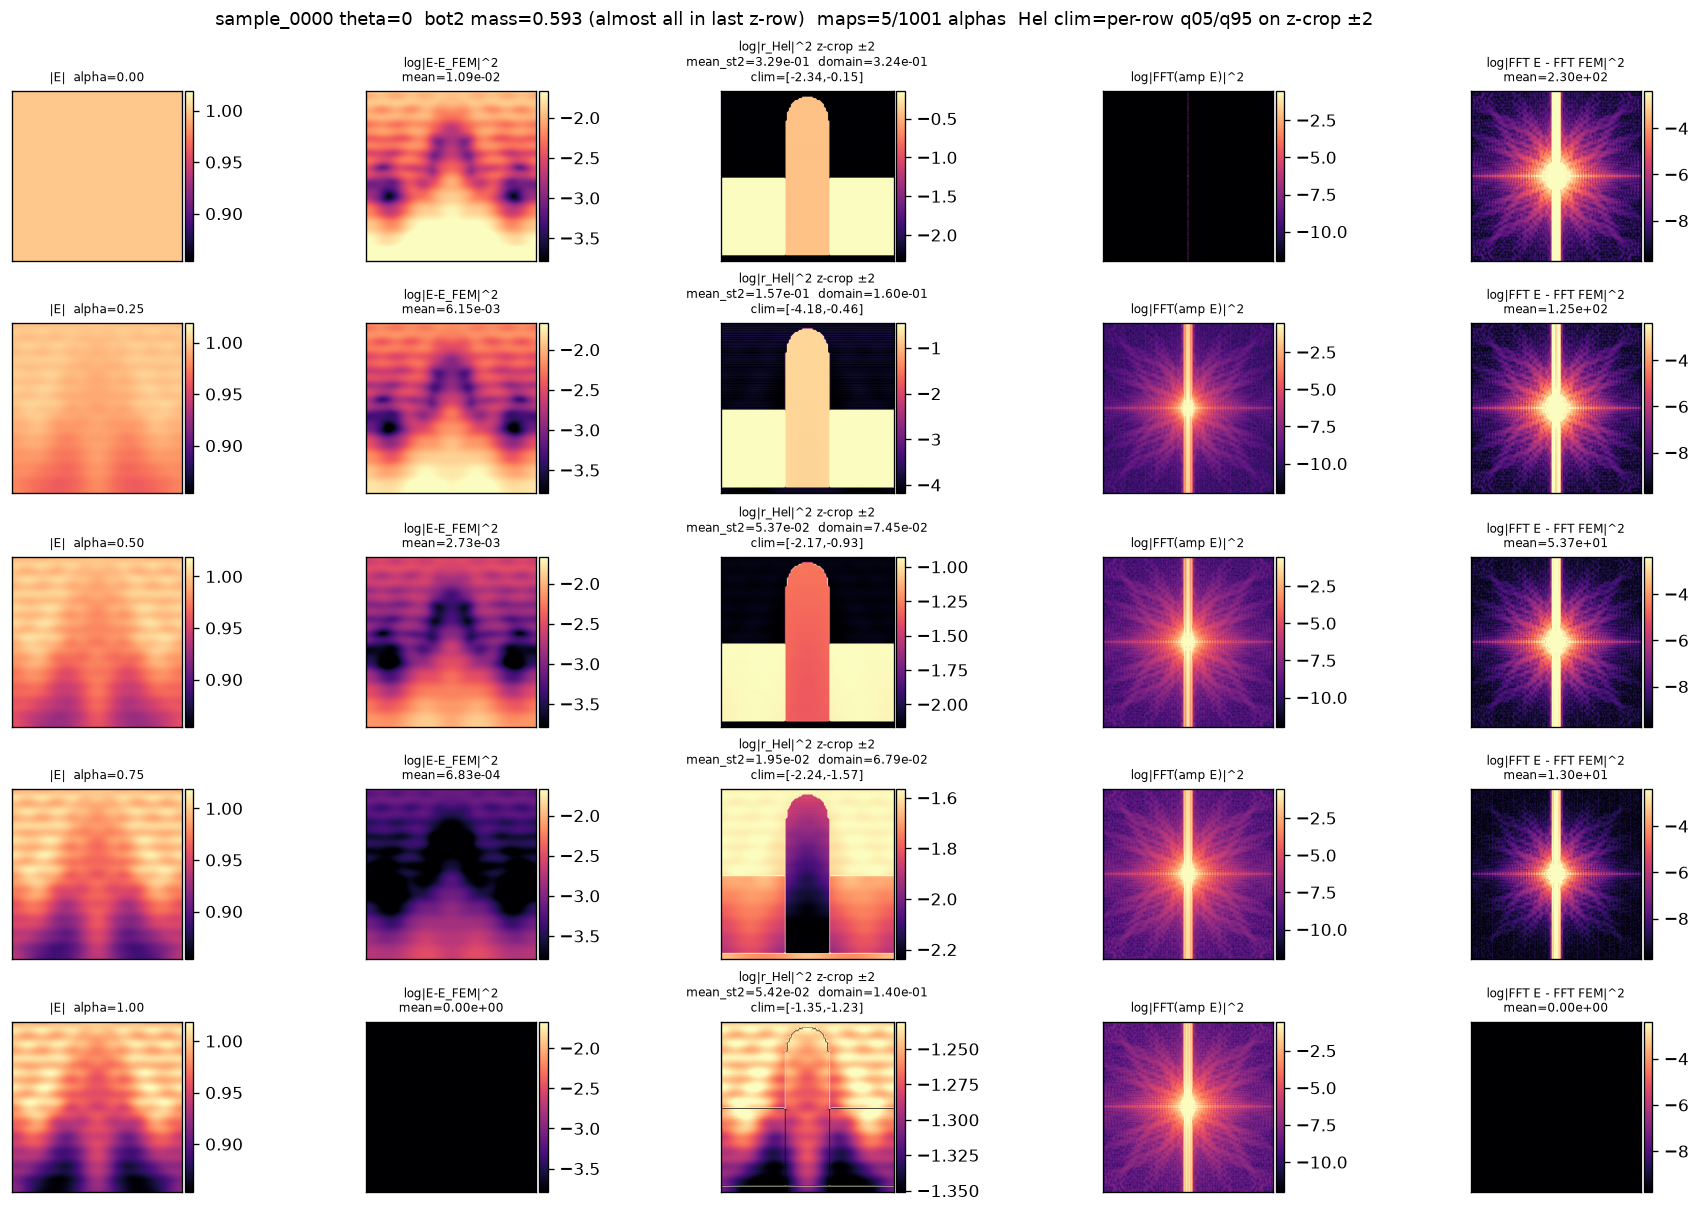

In [10]:
# Image grid uses a sparse alpha subsample; traces/depth use the full dense blend.
map_idx = np.linspace(0, len(blend["alphas"]) - 1, N_ALPHA_MAPS).round().astype(int)
map_idx = np.unique(map_idx)


def _quantile_clim(log_map: torch.Tensor, q_lo: float = 0.05, q_hi: float = 0.95) -> tuple[float, float]:
    """Robust vmin/vmax on a log10 map; falls back to min/max if quantiles collapse."""
    vmin = float(log_map.quantile(q_lo))
    vmax = float(log_map.quantile(q_hi))
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        vmin = float(log_map.min())
        vmax = float(log_map.max())
    if vmax <= vmin:
        vmax = vmin + 1e-12
    return vmin, vmax


abs_stack = torch.stack([blend["e_total"][i].abs() for i in map_idx])
abs_vmin, abs_vmax = float(abs_stack.min()), float(abs_stack.max())
sup_log = torch.log10(torch.stack([blend["sup_maps"][i] for i in map_idx]).clamp_min(1e-12))
hel_st_maps = [blend["hel_maps"][i][STENCIL_EDGE:-STENCIL_EDGE] for i in map_idx]
fft_stack = torch.stack([blend["fft_log_maps"][i] for i in map_idx])
fft_clim = (
    min(float(fft_stack.quantile(0.02)), float(blend["fem_fft_log"].quantile(0.02))),
    max(float(fft_stack.quantile(0.98)), float(blend["fem_fft_log"].quantile(0.98))),
)
fft_sup_log = torch.log10(torch.stack([blend["fft_sup_maps"][i] for i in map_idx]).clamp_min(1e-12))
if len(map_idx) > 1:
    # Exclude alpha=1 (exact zero supervised) from shared clim.
    sup_clim = (float(sup_log[:-1].quantile(0.05)), float(sup_log[:-1].quantile(0.95)))
    fft_sup_clim = (float(fft_sup_log[:-1].quantile(0.05)), float(fft_sup_log[:-1].quantile(0.95)))
else:
    sup_clim = (float(sup_log.min()), float(sup_log.max()))
    fft_sup_clim = (float(fft_sup_log.min()), float(fft_sup_log.max()))

n = len(map_idx)
fig, axes = plt.subplots(n, 5, figsize=(15, 2.0 * n), constrained_layout=True)
if n == 1:
    axes = np.asarray([axes])

for row, i in enumerate(map_idx):
    a = blend["alphas"][i]
    hel_log = torch.log10(hel_st_maps[row].clamp_min(1e-12))
    hel_vmin, hel_vmax = _quantile_clim(hel_log)
    hel_show = hel_log.numpy().clip(hel_vmin, hel_vmax)
    panels = [
        (blend["e_total"][i].abs().numpy(), "magma", abs_vmin, abs_vmax, f"|E|  alpha={a:.2f}"),
        (torch.log10(blend["sup_maps"][i].clamp_min(1e-12)).numpy(), "magma", *sup_clim,
         f"log|E-E_FEM|^2\nmean={blend['sup_mean'][i]:.2e}"),
        (hel_show, "magma", hel_vmin, hel_vmax,
         f"log|r_Hel|^2 z-crop ±{STENCIL_EDGE}\n"
         f"mean_st2={blend['hel_stats']['mean_st2'][i]:.2e}  domain={blend['hel_all'][i]:.2e}\n"
         f"clim=[{hel_vmin:.2f},{hel_vmax:.2f}]"),
        (blend["fft_log_maps"][i].numpy(), "magma", *fft_clim, "log|FFT(amp E)|^2"),
        (torch.log10(blend["fft_sup_maps"][i].clamp_min(1e-12)).numpy(), "magma", *fft_sup_clim,
         f"log|FFT E - FFT FEM|^2\nmean={blend['fft_sup_mean'][i]:.2e}"),
    ]
    for ax, (img, cmap, vmin, vmax, title) in zip(axes[row], panels):
        im = ax.imshow(img, origin="lower", aspect="equal", cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title, fontsize=7)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.01)

fig.suptitle(
    f"{blend['key'][0]} theta={blend['key'][1]:g}  "
    f"bot2 mass={blend['mass_bot2']:.3f} (almost all in last z-row)  "
    f"maps={n}/{len(blend['alphas'])} alphas  "
    f"Hel clim=per-row q05/q95 on z-crop ±{STENCIL_EDGE}",
    fontsize=11,
)
plt.show()


Canonical FD-valid loss: drop z-rows [:2] and [-2:] only (no x crop). Yellow star: min at alpha=0.7490, mean|r|^2=1.9478e-02.


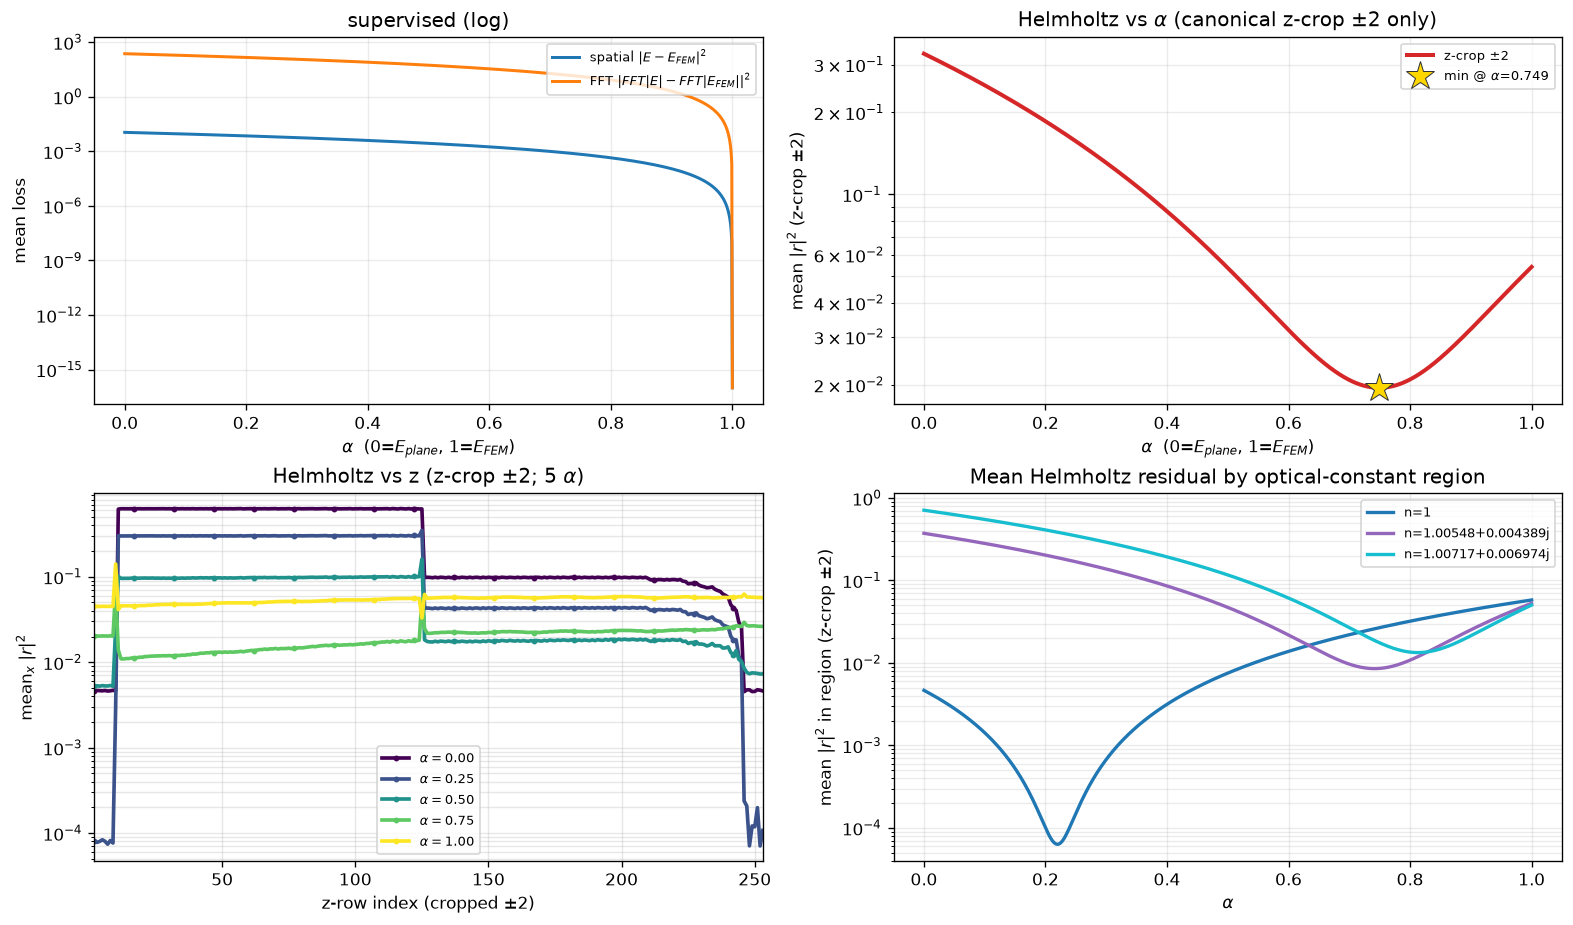

supervised  1.0926e-02 -> 0.0000e+00
FFT sup     2.2963e+02 -> 0.0000e+00
hel domain  3.2377e-01 -> 1.4000e-01
hel z±2    3.2883e-01 -> 5.4162e-02
hel z-crop min @ alpha=0.7490: 1.9478e-02


In [11]:
def _loggable(vals, floor=1e-16):
    return [max(float(v), floor) for v in vals]


alphas = np.asarray(blend["alphas"], dtype=float)
n_alpha = len(alphas)
oc_names = blend["oc_names"]
oc_colors = blend["oc_colors"]
se = blend["stencil_edge"]
cmap_alpha = plt.cm.viridis
norm_alpha = plt.Normalize(vmin=0.0, vmax=1.0)

fig, axes = plt.subplots(2, 2, figsize=(13.0, 7.6), constrained_layout=True)

ax = axes[0, 0]
ax.plot(alphas, _loggable(blend["sup_mean"]), lw=1.8, label=r"spatial $|E-E_{FEM}|^2$")
ax.plot(alphas, _loggable(blend["fft_sup_mean"]), lw=1.8, label=r"FFT $|FFT|E|-FFT|E_{FEM}||^2$")
ax.set_yscale("log")
ax.set_xlabel(r"$\alpha$  (0=$E_{plane}$, 1=$E_{FEM}$)")
ax.set_ylabel("mean loss")
ax.set_title("supervised (log)")
ax.legend(fontsize=8, loc="upper right")
ax.grid(True, which="both", alpha=0.25)

ax = axes[0, 1]
stats = blend["hel_stats"]
hel_z2 = np.asarray(_loggable(stats["mean_st2"]))
ax.plot(
    alphas,
    hel_z2,
    color="C3",
    ls="-",
    lw=2.4,
    label=rf"z-crop $\pm${se}",
)
imin = int(np.argmin(hel_z2))
ax.plot(
    alphas[imin],
    hel_z2[imin],
    marker="*",
    markersize=18,
    color="gold",
    markeredgecolor="0.2",
    markeredgewidth=0.6,
    linestyle="none",
    zorder=5,
    label=rf"min @ $\alpha$={alphas[imin]:.3f}",
)
ax.set_yscale("log")
ax.set_xlabel(r"$\alpha$  (0=$E_{plane}$, 1=$E_{FEM}$)")
ax.set_ylabel(rf"mean $|r|^2$ (z-crop $\pm${se})")
ax.set_title(rf"Helmholtz vs $\alpha$ (canonical z-crop $\pm${se} only)")
ax.legend(fontsize=8, loc="best")
ax.grid(True, which="both", alpha=0.25)
print(
    f"Canonical FD-valid loss: drop z-rows [:{se}] and [-{se}:] only (no x crop). "
    f"Yellow star: min at alpha={alphas[imin]:.4f}, mean|r|^2={hel_z2[imin]:.4e}."
)

ax = axes[1, 0]
nz = blend["hel_maps"][0].shape[0]
z_st = np.arange(se, nz - se)
depth_alphas = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
depth_idx = [int(np.argmin(np.abs(alphas - a))) for a in depth_alphas]
depth_idx = list(dict.fromkeys(depth_idx))
colors = cmap_alpha(norm_alpha(np.array([float(alphas[i]) for i in depth_idx])))
y_lo, y_hi = np.inf, 0.0
for i, color in zip(depth_idx, colors):
    a = float(alphas[i])
    # Only the z-cropped band; mean over full x (periodic edges kept).
    prof = blend["hel_z_st2"][i].numpy()
    ax.semilogy(z_st, prof, color=color, ls="-", lw=2.2, marker="o", markersize=2.5,
                markevery=max(len(z_st) // 16, 1), label=rf"$\alpha={a:.2f}$")
    pos = prof[np.isfinite(prof) & (prof > 0)]
    if pos.size:
        y_lo = min(y_lo, float(pos.min()))
        y_hi = max(y_hi, float(pos.max()))
if np.isfinite(y_lo) and y_hi > y_lo:
    ax.set_ylim(y_lo / 1.5, y_hi * 1.5)
ax.set_xlim(z_st[0], z_st[-1])
ax.set_xlabel(rf"z-row index (cropped $\pm${se})")
ax.set_ylabel(r"mean$_x$ $|r|^2$")
ax.set_title(rf"Helmholtz vs z (z-crop $\pm${se}; 5 $\alpha$)")
ax.legend(fontsize=8, loc="best")
ax.grid(True, which="both", alpha=0.3)

ax = axes[1, 1]
for name in oc_names:
    heights = [reg[name] for reg in blend["hel_rmse_oc"]]
    ax.semilogy(
        alphas,
        _loggable(heights),
        color=oc_colors[name],
        lw=2.0,
        label=name,
    )
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(rf"mean $|r|^2$ in region (z-crop $\pm${se})")
ax.set_title("Mean Helmholtz residual by optical-constant region")
ax.legend(fontsize=8, loc="best")
ax.grid(True, which="both", alpha=0.25)

plt.show()

print(
    f"supervised  {blend['sup_mean'][0]:.4e} -> {blend['sup_mean'][-1]:.4e}\n"
    f"FFT sup     {blend['fft_sup_mean'][0]:.4e} -> {blend['fft_sup_mean'][-1]:.4e}\n"
    f"hel domain  {blend['hel_all'][0]:.4e} -> {blend['hel_all'][-1]:.4e}\n"
    f"hel z±{se}    {blend['hel_stats']['mean_st2'][0]:.4e} -> {blend['hel_stats']['mean_st2'][-1]:.4e}\n"
    f"hel z-crop min @ alpha={alphas[imin]:.4f}: {hel_z2[imin]:.4e}"
)


## 7. Comparison with phase-screen baseline

Same blend machinery as §6, but $\alpha=0$ is the matched incident with a **smooth
phase jitter locked to the plane-wave fringe scale**:

$$
E(\alpha)=\alpha\,E_{\mathrm{FEM}}+(1-\alpha)\,E_i\,e^{i\phi},\qquad
\phi\sim\mathrm{GP},\ \ell\approx\mathrm{period}(E_i)
$$

So the carrier phase of $E_i$ is kept and perturbations live on the same spatial
scale as the plane-wave fringes (not large arbitrary blobs). Alpha is coarse on
$[0,0.9]$ and dense on $[0.9,1]$. Field maps zoom to
$\alpha\in\{0.9,0.925,0.95,0.975,1\}$. Helmholtz uses canonical z-crop $\pm 2$.


E(alpha)=alpha*E_FEM + (1-alpha)*E_i*exp(i phi)  seed=0 corr_px=42.6667 (fringe-matched) phase_std=1  n_alpha=1000 (coarse=201, fine=800 from 0.9)  mean|E|=1.0000  L2=1.0000
alpha        sup        hel    hel_st2    fft_sup
 0.00 8.1522e-01 2.1138e+02 1.8075e+02 2.2963e+02
 0.22 4.8964e-01 1.2714e+02 1.0850e+02 8.9015e+02
 0.45 2.4660e-01 6.4213e+01 5.4598e+01 2.4581e+03
 0.67 8.6108e-02 2.2606e+01 1.9037e+01 1.8613e+03
 0.90 8.1522e-03 2.3158e+00 1.8188e+00 2.4345e+02
 0.91 7.1638e-03 2.0561e+00 1.6021e+00 2.1525e+02
 0.91 6.2393e-03 1.8129e+00 1.3996e+00 1.8860e+02
 0.92 5.3786e-03 1.5863e+00 1.2112e+00 1.6355e+02
 0.93 4.5818e-03 1.3761e+00 1.0371e+00 1.4014e+02
 0.93 3.8488e-03 1.1824e+00 8.7715e-01 1.1839e+02
 0.94 3.1797e-03 1.0051e+00 7.3139e-01 9.8364e+01
 0.94 2.5744e-03 8.4443e-01 5.9982e-01 8.0082e+01
 0.95 2.0330e-03 7.0019e-01 4.8245e-01 6.3585e+01
 0.96 1.5554e-03 5.7244e-01 3.7926e-01 4.8909e+01
 0.96 1.1416e-03 4.6119e-01 2.9026e-01 3.6089e+01
 0.97 7.9174e-04 3.6642e-0

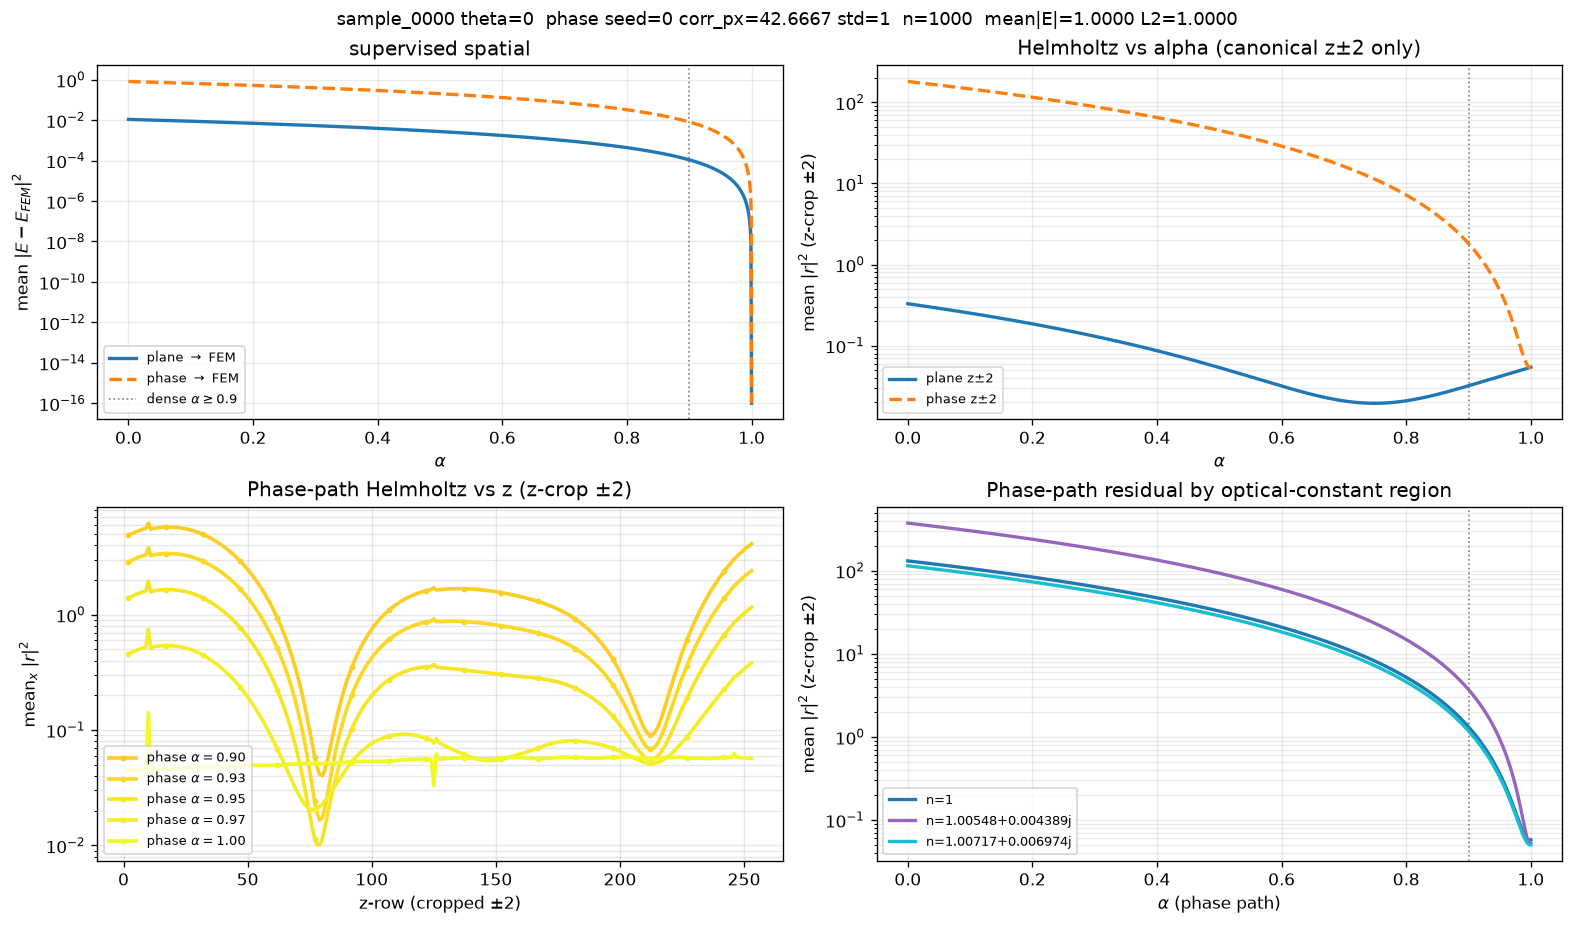

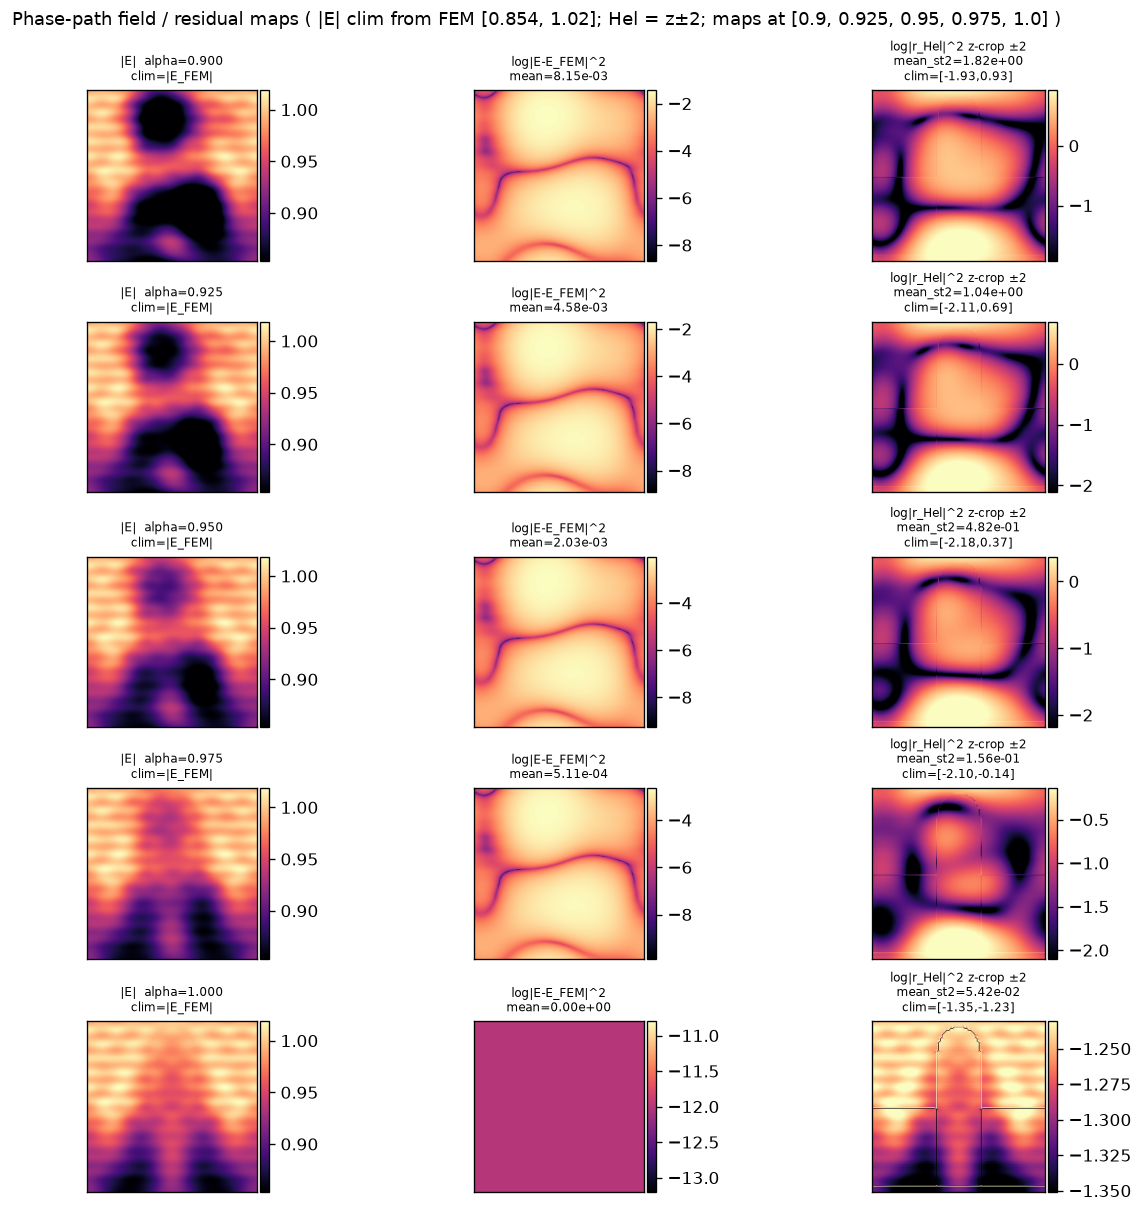

In [12]:
RANDOM_SEED = 0
PRINT_STRIDE = max(1, N_ALPHA // 20)
PHASE_STD = 1.0  # radians of phase jitter on top of the plane-wave carrier
PHASE_CORR_SCALE = 1.0  # multiply inferred plane-wave fringe period (pixels)
ALPHA_FINE_START = 0.9
N_ALPHA_COARSE = max(201, N_ALPHA // 5)  # [0, 0.9]
N_ALPHA_FINE = max(401, (4 * N_ALPHA) // 5)  # [0.9, 1], denser
MAP_ALPHAS = (0.9, 0.925, 0.95, 0.975, 1.0)


def _loggable(vals, floor=1e-16):
    return [max(float(v), floor) for v in vals]


def _quantile_clim(log_map: torch.Tensor, q_lo: float = 0.05, q_hi: float = 0.95) -> tuple[float, float]:
    """Robust vmin/vmax on a log10 map; falls back to min/max if quantiles collapse."""
    vmin = float(log_map.quantile(q_lo))
    vmax = float(log_map.quantile(q_hi))
    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmax <= vmin:
        vmin = float(log_map.min())
        vmax = float(log_map.max())
    if vmax <= vmin:
        vmax = vmin + 1e-12
    return vmin, vmax


def make_alpha_grid(
    n_coarse: int = N_ALPHA_COARSE,
    n_fine: int = N_ALPHA_FINE,
    fine_start: float = ALPHA_FINE_START,
    device: str | torch.device = DEVICE,
) -> torch.Tensor:
    """Coarse [0, fine_start] then dense [fine_start, 1], no duplicate knot.

    Parameters
    ----------
    n_coarse, n_fine : int
        Sample counts on the early and late segments (>=2).
    fine_start : float
        Break point in (0, 1).
    device : str or torch.device
        Device for both segments (required for ``torch.cat``).

    Returns
    -------
    torch.Tensor
        1-D increasing alpha grid on ``device``.
    """
    a0 = torch.linspace(0.0, float(fine_start), int(n_coarse), device=device)
    a1 = torch.linspace(float(fine_start), 1.0, int(n_fine), device=device)[1:]
    return torch.cat([a0, a1])


def plane_wave_period_px(e_ref: torch.Tensor) -> float:
    """Infer dominant fringe period (pixels) from the FFT peak of ``e_ref``.

    Parameters
    ----------
    e_ref : torch.Tensor
        Complex field ``(..., Nz, Nx)``.

    Returns
    -------
    float
        Spatial period of the strongest non-DC Fourier mode in pixels.
    """
    e2 = e_ref[0] if e_ref.ndim == 3 else e_ref
    nz, nx = int(e2.shape[-2]), int(e2.shape[-1])
    F = torch.fft.fftshift(torch.fft.fft2(e2))
    mag = F.abs()
    # suppress DC neighborhood so the carrier sideband wins
    cz, cx = nz // 2, nx // 2
    mag = mag.clone()
    mag[cz - 1 : cz + 2, cx - 1 : cx + 2] = 0
    flat = int(torch.argmax(mag.reshape(-1)))
    iz, ix = divmod(flat, nx)
    fy = float(iz - cz) / float(nz)
    fx = float(ix - cx) / float(nx)
    freq = (fy**2 + fx**2) ** 0.5
    if freq < 1e-8:
        return float(min(nz, nx)) / 8.0
    return float(1.0 / freq)


def make_phase_screen_e(
    e_ref: torch.Tensor,
    seed: int = RANDOM_SEED,
    corr_px: float | None = None,
    phase_std: float = PHASE_STD,
) -> tuple[torch.Tensor, float]:
    """Plane-wave carrier with smooth phase jitter at the fringe scale.

    Builds ``E = E_ref * exp(i phi)`` so the matched-incident phase is preserved
    as the carrier and ``phi`` is a real spectral GP whose correlation length
    matches the dominant plane-wave period of ``E_ref`` (unless ``corr_px`` is
    set). Spatial structure then sits on the same scale as the plane-wave
    fringes rather than large arbitrary blobs.

    Parameters
    ----------
    e_ref : torch.Tensor
        Reference total field (matched incident). Complex, any batch layout.
    seed : int
        CPU generator seed for reproducibility.
    corr_px : float or None
        Phase correlation length in pixels. ``None`` => ``PHASE_CORR_SCALE``
        times ``plane_wave_period_px(e_ref)``.
    phase_std : float
        Standard deviation of ``phi`` in radians (>0).

    Returns
    -------
    field : torch.Tensor
        Complex field on ``e_ref.device`` with the same ``|E|`` as ``e_ref``.
    corr_px_used : float
        Correlation length actually applied.
    """
    gen = torch.Generator(device="cpu")
    gen.manual_seed(seed)
    shape = tuple(e_ref.shape)
    nz, nx = int(shape[-2]), int(shape[-1])
    if corr_px is None:
        corr_px = max(PHASE_CORR_SCALE * plane_wave_period_px(e_ref), 1.0)
    else:
        corr_px = max(float(corr_px), 1.0)
    n_lead = int(np.prod(shape[:-2])) if len(shape) > 2 else 1

    def _phase_2d() -> torch.Tensor:
        w = torch.randn(nz, nx, generator=gen, dtype=torch.float32)
        W = torch.fft.fft2(w)
        ky = torch.fft.fftfreq(nz).reshape(-1, 1)
        kx = torch.fft.fftfreq(nx).reshape(1, -1)
        k2 = (2.0 * np.pi) ** 2 * (ky.pow(2) + kx.pow(2))
        filt = torch.exp(-0.5 * k2 * (corr_px**2))
        phi = torch.fft.ifft2(W * filt.to(W.dtype)).real
        phi = phi - phi.mean()
        std = phi.std().clamp_min(1e-30)
        return phi * (float(phase_std) / std)

    pieces = [_phase_2d() for _ in range(n_lead)]
    phi = pieces[0] if len(shape) == 2 else torch.stack(pieces, dim=0).reshape(*shape)
    phi = phi.to(device=e_ref.device, dtype=torch.float32)
    field = e_ref * torch.exp(1j * phi.to(dtype=e_ref.real.dtype))
    return field, float(corr_px)


def collect_blend_random(
    key: tuple[str, float],
    n_coarse: int = N_ALPHA_COARSE,
    n_fine: int = N_ALPHA_FINE,
    seed: int = RANDOM_SEED,
) -> dict:
    """E(alpha)=alpha*E_FEM+(1-alpha)*phase_screen(E_i); Helmholtz uses matched E_i."""
    if mode != "te":
        raise NotImplementedError("TE-only debug path")

    r = reports[key]
    batch = batches[key]
    e_inc = r["incident_matched"].to(DEVICE)
    e_fem = r["e_fem"].to(DEVICE)
    eps = r["eps"].to(DEVICE)
    kz = r["kz"].to(DEVICE)
    kx = r["kx"].to(DEVICE)

    e_random, corr_px_used = make_phase_screen_e(e_inc, seed=seed)
    e_inc2 = e_inc[0] if e_inc.ndim == 3 else e_inc
    e_rand2 = e_random[0] if e_random.ndim == 3 else e_random
    e_fem2 = e_fem[0] if e_fem.ndim == 3 else e_fem
    fem_spec = fft_amp_spectrum(e_fem2)
    fem_fft_log = _fft_log_intensity(e_fem2.abs())

    n_map = optical_n_map(batch, mode).to(DEVICE)
    oc_labels, oc_names, oc_colors, _ = unique_optical_labels(n_map)
    n_class = len(oc_names)

    alphas = make_alpha_grid(n_coarse=n_coarse, n_fine=n_fine, device=DEVICE)
    e_total_maps, sup_maps, hel_maps = [], [], []
    fft_log_maps, fft_sup_maps = [], []
    sup_mean, fft_sup_mean = [], []
    hel_all, hel_in = [], []
    hel_stats = {
        "mean": [],
        "p75": [],
        "mean_st2": [],
        "p75_st2": [],
        "mean_oc": [],
        "p75_oc": [],
    }
    hel_rmse_oc: list[dict[str, float]] = []
    hel_z_st2: list[torch.Tensor] = []

    se = STENCIL_EDGE
    ie = INTERIOR_EDGE
    for a in alphas:
        e = (1.0 - a) * e_random + a * e_fem
        residual, _ = helmholtz_of_total(e, eps, e_inc, kz, kx, batch)
        e2 = e[0] if e.ndim == 3 else e
        r2 = residual.abs().pow(2)
        r2 = r2[0] if r2.ndim == 3 else r2
        s2 = (e2 - e_fem2).abs().pow(2)
        spec = fft_amp_spectrum(e2)
        fft_sup = (spec - fem_spec).abs().pow(2)

        r2_st2 = r2[se:-se] if r2.shape[0] > 2 * se else r2
        lab_st2 = oc_labels[se:-se] if oc_labels.shape[0] > 2 * se else oc_labels
        z_st2 = r2_st2.mean(dim=-1).detach().cpu()

        m, q = r2_mean_p75(r2.reshape(-1))
        ms, qs = r2_mean_p75(r2_st2.reshape(-1))
        mo, qo = oc_balanced_mean_p75(r2, oc_labels, n_class)

        e_total_maps.append(e2.detach().cpu())
        sup_maps.append(s2.detach().cpu())
        hel_maps.append(r2.detach().cpu())
        hel_z_st2.append(z_st2)
        fft_log_maps.append(_fft_log_intensity(e2.abs()).detach().cpu())
        fft_sup_maps.append(fft_sup.detach().cpu())
        sup_mean.append(float(s2.mean()))
        fft_sup_mean.append(float(fft_sup.mean()))
        hel_all.append(float(r2.mean()))
        hel_in.append(float(r2[ie:-ie].mean()) if r2.shape[0] > 2 * ie else float(r2.mean()))
        hel_stats["mean"].append(m)
        hel_stats["p75"].append(q)
        hel_stats["mean_st2"].append(ms)
        hel_stats["p75_st2"].append(qs)
        hel_stats["mean_oc"].append(mo)
        hel_stats["p75_oc"].append(qo)
        hel_rmse_oc.append(rmse_by_optical(r2_st2, lab_st2, oc_names))

    l2_ratio = float(
        torch.linalg.vector_norm(e_random) / torch.linalg.vector_norm(e_inc).clamp_min(1e-30)
    )
    mean_abs_ratio = float(e_random.abs().mean() / e_inc.abs().mean().clamp_min(1e-30))
    n_alpha_tot = int(alphas.numel())
    print(
        f"E(alpha)=alpha*E_FEM + (1-alpha)*E_i*exp(i phi)  "
        f"seed={seed} corr_px={corr_px_used:g} (fringe-matched) phase_std={PHASE_STD:g}  "
        f"n_alpha={n_alpha_tot} (coarse={n_coarse}, fine={n_fine} from {ALPHA_FINE_START:g})  "
        f"mean|E|={mean_abs_ratio:.4f}  L2={l2_ratio:.4f}"
    )
    print(f"{'alpha':>5} {'sup':>10} {'hel':>10} {'hel_st2':>10} {'fft_sup':>10}")
    print_idx = list(range(0, n_alpha_tot, max(1, n_alpha_tot // 20)))
    if print_idx[-1] != n_alpha_tot - 1:
        print_idx.append(n_alpha_tot - 1)
    for i in print_idx:
        a = float(alphas[i].detach().cpu())
        print(
            f"{a:5.2f} {sup_mean[i]:10.4e} {hel_all[i]:10.4e} "
            f"{hel_stats['mean_st2'][i]:10.4e} {fft_sup_mean[i]:10.4e}"
        )

    return {
        "key": key,
        "seed": seed,
        "corr_px": corr_px_used,
        "phase_std": PHASE_STD,
        "alphas": alphas.detach().cpu().numpy(),
        "e_incident": e_inc2.detach().cpu(),
        "e_random": e_rand2.detach().cpu(),
        "e_fem": e_fem2.detach().cpu(),
        "fem_fft_log": fem_fft_log.detach().cpu(),
        "e_total": e_total_maps,
        "sup_maps": sup_maps,
        "hel_maps": hel_maps,
        "hel_z_st2": hel_z_st2,
        "fft_log_maps": fft_log_maps,
        "fft_sup_maps": fft_sup_maps,
        "sup_mean": sup_mean,
        "fft_sup_mean": fft_sup_mean,
        "hel_all": hel_all,
        "hel_in": hel_in,
        "hel_stats": hel_stats,
        "hel_rmse_oc": hel_rmse_oc,
        "oc_names": oc_names,
        "oc_colors": oc_colors,
        "oc_labels": oc_labels.detach().cpu(),
        "n_map": n_map.detach().cpu(),
        "norm_ratio": mean_abs_ratio,
        "l2_ratio": l2_ratio,
        "stencil_edge": se,
    }


blend_random = collect_blend_random(BLEND_KEY)

se = STENCIL_EDGE
rows = [
    ("plane alpha=0", blend["sup_mean"][0], blend["hel_stats"]["mean_st2"][0]),
    ("phase alpha=0", blend_random["sup_mean"][0], blend_random["hel_stats"]["mean_st2"][0]),
    ("plane alpha=1", blend["sup_mean"][-1], blend["hel_stats"]["mean_st2"][-1]),
    ("phase alpha=1", blend_random["sup_mean"][-1], blend_random["hel_stats"]["mean_st2"][-1]),
]
print()
print(f"{'endpoint':>16s} {'sup':>12s} {f'hel_z±{se}':>12s}")
for name, s, hz in rows:
    print(f"{name:>16s} {s:12.4e} {hz:12.4e}")
ratio_st2 = blend_random["hel_stats"]["mean_st2"][0] / max(blend["hel_stats"]["mean_st2"][0], 1e-30)
ratio_sup = blend_random["sup_mean"][0] / max(blend["sup_mean"][0], 1e-30)
print(f"alpha=0 phase/plane  sup={ratio_sup:.3e}  hel_z±{se}={ratio_st2:.3e}")

alphas_p = np.asarray(blend["alphas"], dtype=float)
alphas_r = np.asarray(blend_random["alphas"], dtype=float)

fig, axes = plt.subplots(2, 2, figsize=(13.0, 7.6), constrained_layout=True)

ax = axes[0, 0]
ax.plot(alphas_p, _loggable(blend["sup_mean"]), lw=2.0, color="C0", label=r"plane $\to$ FEM")
ax.plot(alphas_r, _loggable(blend_random["sup_mean"]), lw=2.0, color="C1", ls="--", label=r"phase $\to$ FEM")
ax.axvline(ALPHA_FINE_START, color="0.5", ls=":", lw=1.0, label=rf"dense $\alpha\geq ${ALPHA_FINE_START:g}")
ax.set_yscale("log")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"mean $|E-E_{FEM}|^2$")
ax.set_title("supervised spatial")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.25)

ax = axes[0, 1]
ax.plot(
    alphas_p,
    _loggable(blend["hel_stats"]["mean_st2"]),
    lw=2.0,
    color="C0",
    label=rf"plane z$\pm${se}",
)
ax.plot(
    alphas_r,
    _loggable(blend_random["hel_stats"]["mean_st2"]),
    lw=2.0,
    color="C1",
    ls="--",
    label=rf"phase z$\pm${se}",
)
ax.axvline(ALPHA_FINE_START, color="0.5", ls=":", lw=1.0)
ax.set_yscale("log")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(rf"mean $|r|^2$ (z-crop $\pm${se})")
ax.set_title(rf"Helmholtz vs alpha (canonical z$\pm${se} only)")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.25)

ax = axes[1, 0]
nz = blend_random["hel_maps"][0].shape[0]
z_st = np.arange(se, nz - se)
depth_alphas = np.asarray(MAP_ALPHAS, dtype=float)
depth_idx = [int(np.argmin(np.abs(alphas_r - a))) for a in depth_alphas]
depth_idx = list(dict.fromkeys(depth_idx))
cmap_alpha = plt.cm.plasma
norm_alpha = plt.Normalize(vmin=0.0, vmax=1.0)
for i in depth_idx:
    a = float(alphas_r[i])
    color = cmap_alpha(norm_alpha(a))
    ax.semilogy(
        z_st,
        blend_random["hel_z_st2"][i].numpy(),
        color=color,
        lw=2.2,
        marker="o",
        markersize=2.5,
        markevery=max(len(z_st) // 16, 1),
        label=rf"phase $\alpha={a:.2f}$",
    )
ax.set_xlabel(rf"z-row (cropped $\pm${se})")
ax.set_ylabel(r"mean$_x$ $|r|^2$")
ax.set_title(rf"Phase-path Helmholtz vs z (z-crop $\pm${se})")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)

ax = axes[1, 1]
for name in blend_random["oc_names"]:
    heights = [reg[name] for reg in blend_random["hel_rmse_oc"]]
    ax.semilogy(
        alphas_r,
        _loggable(heights),
        color=blend_random["oc_colors"][name],
        lw=2.0,
        label=name,
    )
ax.axvline(ALPHA_FINE_START, color="0.5", ls=":", lw=1.0)
ax.set_xlabel(r"$\alpha$ (phase path)")
ax.set_ylabel(rf"mean $|r|^2$ (z-crop $\pm${se})")
ax.set_title("Phase-path residual by optical-constant region")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.25)

fig.suptitle(
    f"{blend_random['key'][0]} theta={blend_random['key'][1]:g}  "
    f"phase seed={blend_random['seed']} corr_px={blend_random['corr_px']:g} "
    f"std={blend_random['phase_std']:g}  n={len(alphas_r)}  "
    f"mean|E|={blend_random['norm_ratio']:.4f} L2={blend_random['l2_ratio']:.4f}",
    fontsize=11,
)
plt.show()

map_alphas = np.asarray(MAP_ALPHAS, dtype=float)
map_idx = [int(np.argmin(np.abs(alphas_r - a))) for a in map_alphas]
map_idx = list(dict.fromkeys(map_idx))
n = len(map_idx)
e_fem_abs = blend_random["e_fem"].abs()
abs_vmin, abs_vmax = float(e_fem_abs.min()), float(e_fem_abs.max())
hel_st_maps = [blend_random["hel_maps"][i][se:-se] for i in map_idx]

fig, axes = plt.subplots(n, 3, figsize=(10, 2.0 * n), constrained_layout=True)
if n == 1:
    axes = np.asarray([axes])
for row, i in enumerate(map_idx):
    a = alphas_r[i]
    hel_log = torch.log10(hel_st_maps[row].clamp_min(1e-12))
    hel_vmin, hel_vmax = _quantile_clim(hel_log)
    hel_show = hel_log.numpy().clip(hel_vmin, hel_vmax)
    panels = [
        (
            blend_random["e_total"][i].abs().numpy(),
            "magma",
            abs_vmin,
            abs_vmax,
            f"|E|  alpha={a:.3f}\nclim=|E_FEM|",
        ),
        (
            torch.log10(blend_random["sup_maps"][i].clamp_min(1e-12)).numpy(),
            "magma",
            None,
            None,
            f"log|E-E_FEM|^2\nmean={blend_random['sup_mean'][i]:.2e}",
        ),
        (
            hel_show,
            "magma",
            hel_vmin,
            hel_vmax,
            f"log|r_Hel|^2 z-crop ±{se}\n"
            f"mean_st2={blend_random['hel_stats']['mean_st2'][i]:.2e}\n"
            f"clim=[{hel_vmin:.2f},{hel_vmax:.2f}]",
        ),
    ]
    for ax, (img, cmap, vmin, vmax, title) in zip(axes[row], panels):
        kw = {"origin": "lower", "aspect": "equal", "cmap": cmap}
        if vmin is not None:
            kw["vmin"] = vmin
            kw["vmax"] = vmax
        im = ax.imshow(img, **kw)
        ax.set_title(title, fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.01)
fig.suptitle(
    "Phase-path field / residual maps "
    f"( |E| clim from FEM [{abs_vmin:.3g}, {abs_vmax:.3g}]; "
    f"Hel = z±{se}; maps at {list(np.round(alphas_r[map_idx], 3))} )",
    fontsize=11,
)
plt.show()


## 8. Higher-order Laplacian on the $\alpha$-blend panel

Same plane$\to$FEM blend diagnostics as §6 on **one** 2×2 panel, with FD
orders **2 / 4 / 6** overlaid. Linestyle encodes order: solid = 2, dashed = 4,
dotted = 6. Color still encodes $\alpha$ (vs $z$) or optical-constant region.

Supervised curves are order-independent (plotted once). Helmholtz curves use
`fd_order` on `helmholtz_residual_loss_periodic_pml`.


Plane-wave Laplacian validator (analytic curvature):
order     mean_rel      max_rel
    2   1.7265e-03   1.7518e-03
    4   7.2522e-05   2.4240e-04
    6   8.0092e-05   2.6045e-04



FD order 2: min z-crop |r|^2 at alpha=0.7490, mean=1.9478e-02
FD order 4: min z-crop |r|^2 at alpha=0.6760, mean=3.1785e-02
FD order 6: min z-crop |r|^2 at alpha=0.6760, mean=3.1769e-02


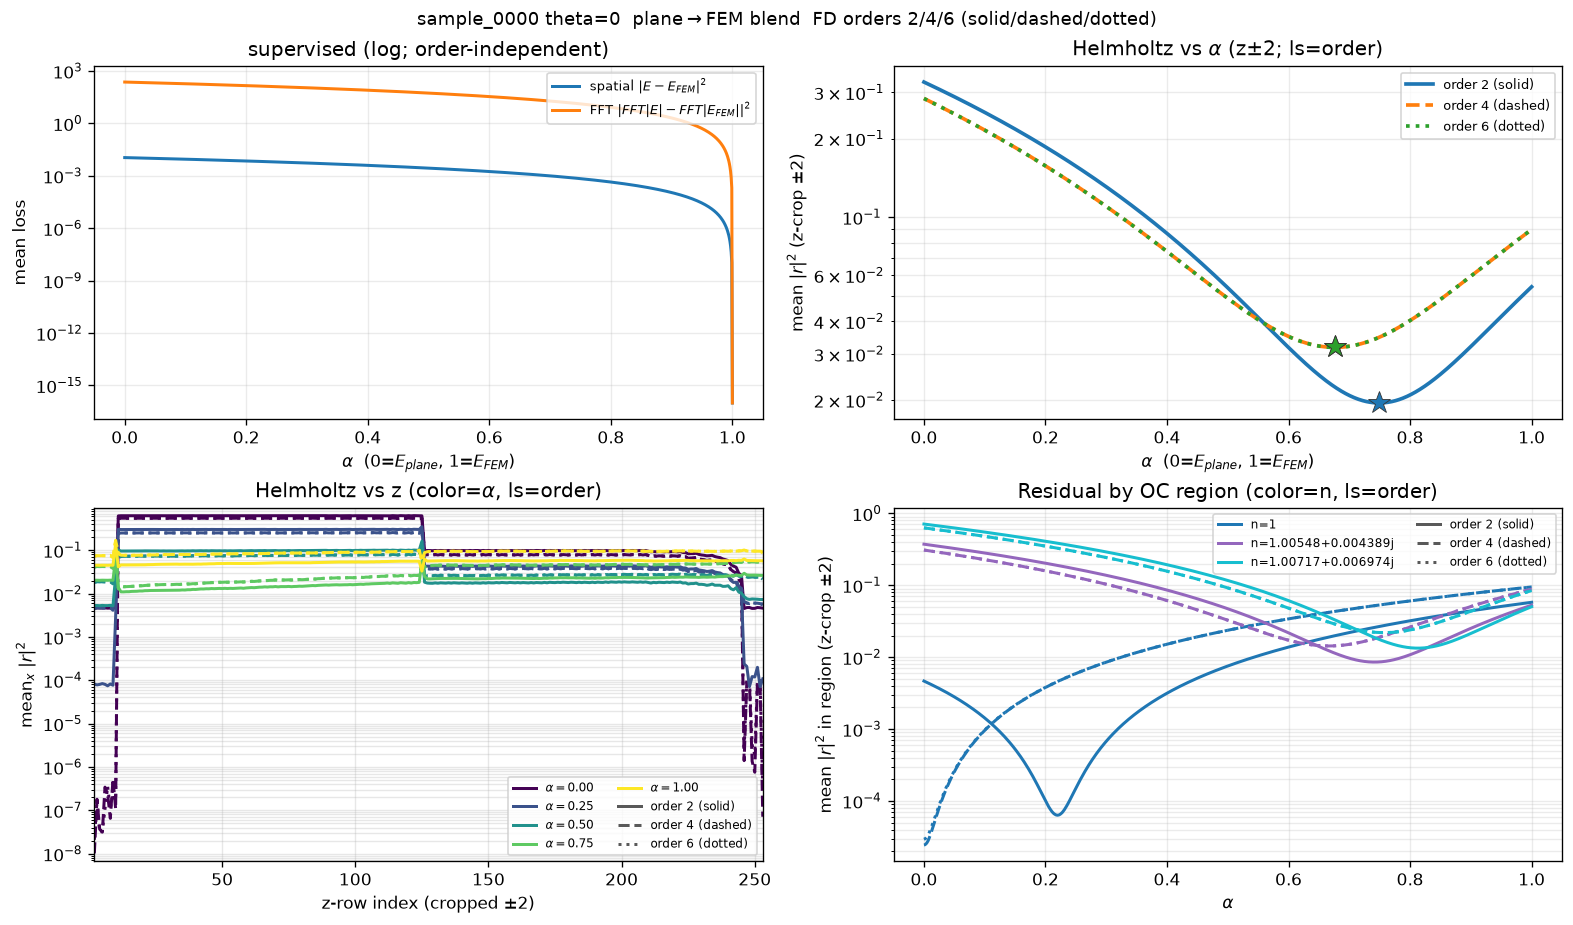

In [15]:
from maxwell_losses.helmholtz_checker import validate_laplacian_orders

FD_ORDERS = (2, 4, 6)


def helmholtz_of_total_order(e_total, eps, incident, kz, kx, batch, fd_order: int):
    """Training Helmholtz residual at a chosen staggered FD order."""
    wavelength_a, dx, dz, kz_n, kx_n = training_units(batch, kz, kx)
    pol_name = batch["pol"][0]
    if mode != "te":
        raise NotImplementedError("order comparison is TE-only")
    envelope = e_total / incident - 1.0
    residual = helmholtz_residual_loss_periodic_pml(
        envelope,
        eps,
        incident,
        kz_n,
        kx_n,
        pol_name,
        wavelength_a,
        dx,
        dz,
        PML_THICKNESS,
        fd_order=fd_order,
    )
    return residual, envelope


def collect_blend_order(
    key: tuple[str, float],
    fd_order: int,
    n_alpha: int = N_ALPHA,
) -> dict:
    """Plane-to-FEM blend with Helmholtz scored at ``fd_order``."""
    if mode != "te":
        raise NotImplementedError("TE-only debug path")

    r = reports[key]
    batch = batches[key]
    e_plane = r["incident_matched"].to(DEVICE)
    e_fem = r["e_fem"].to(DEVICE)
    eps = r["eps"].to(DEVICE)
    kz = r["kz"].to(DEVICE)
    kx = r["kx"].to(DEVICE)

    e_plane2 = e_plane[0] if e_plane.ndim == 3 else e_plane
    e_fem2 = e_fem[0] if e_fem.ndim == 3 else e_fem
    fem_spec = fft_amp_spectrum(e_fem2)

    n_map = optical_n_map(batch, mode).to(DEVICE)
    oc_labels, oc_names, oc_colors, _ = unique_optical_labels(n_map)

    alphas = torch.linspace(0.0, 1.0, n_alpha, device=DEVICE)
    sup_mean, fft_sup_mean = [], []
    hel_stats = {"mean_st2": []}
    hel_rmse_oc: list[dict[str, float]] = []
    hel_z_st2: list[torch.Tensor] = []
    hel_maps: list[torch.Tensor] = []

    se = STENCIL_EDGE
    for a in alphas:
        e = (1.0 - a) * e_plane + a * e_fem
        residual, _ = helmholtz_of_total_order(
            e, eps, e_plane, kz, kx, batch, fd_order
        )
        e2 = e[0] if e.ndim == 3 else e
        r2 = residual.abs().pow(2)
        r2 = r2[0] if r2.ndim == 3 else r2
        s2 = (e2 - e_fem2).abs().pow(2)
        spec = fft_amp_spectrum(e2)
        fft_sup = (spec - fem_spec).abs().pow(2)

        r2_st2 = r2[se:-se] if r2.shape[0] > 2 * se else r2
        lab_st2 = oc_labels[se:-se] if oc_labels.shape[0] > 2 * se else oc_labels
        z_st2 = r2_st2.mean(dim=-1).detach().cpu()
        ms, _ = r2_mean_p75(r2_st2.reshape(-1))

        hel_maps.append(r2.detach().cpu())
        hel_z_st2.append(z_st2)
        sup_mean.append(float(s2.mean()))
        fft_sup_mean.append(float(fft_sup.mean()))
        hel_stats["mean_st2"].append(ms)
        hel_rmse_oc.append(rmse_by_optical(r2_st2, lab_st2, oc_names))

    return {
        "key": key,
        "fd_order": fd_order,
        "alphas": alphas.detach().cpu().numpy(),
        "sup_mean": sup_mean,
        "fft_sup_mean": fft_sup_mean,
        "hel_stats": hel_stats,
        "hel_rmse_oc": hel_rmse_oc,
        "hel_z_st2": hel_z_st2,
        "hel_maps": hel_maps,
        "oc_names": oc_names,
        "oc_colors": oc_colors,
        "stencil_edge": se,
    }


FD_ORDER_LS = {2: "-", 4: "--", 6: ":"}
FD_ORDER_COLOR = {2: "C0", 4: "C1", 6: "C2"}
FD_ORDER_LABEL = {2: "order 2 (solid)", 4: "order 4 (dashed)", 6: "order 6 (dotted)"}


def plot_blend_orders_overlay(blends: dict[int, dict]) -> None:
    """§6-style 2x2 panel with all FD orders overlaid via linestyle."""
    b0 = blends[FD_ORDERS[0]]
    alphas = np.asarray(b0["alphas"], dtype=float)
    se = b0["stencil_edge"]
    oc_names = b0["oc_names"]
    oc_colors = b0["oc_colors"]
    cmap_alpha = plt.cm.viridis
    norm_alpha = plt.Normalize(vmin=0.0, vmax=1.0)

    fig, axes = plt.subplots(2, 2, figsize=(13.0, 7.6), constrained_layout=True)

    ax = axes[0, 0]
    ax.plot(alphas, _loggable(b0["sup_mean"]), lw=1.8, label=r"spatial $|E-E_{FEM}|^2$")
    ax.plot(
        alphas,
        _loggable(b0["fft_sup_mean"]),
        lw=1.8,
        label=r"FFT $|FFT|E|-FFT|E_{FEM}||^2$",
    )
    ax.set_yscale("log")
    ax.set_xlabel(r"$\alpha$  (0=$E_{plane}$, 1=$E_{FEM}$)")
    ax.set_ylabel("mean loss")
    ax.set_title("supervised (log; order-independent)")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, which="both", alpha=0.25)

    ax = axes[0, 1]
    for order in FD_ORDERS:
        b = blends[order]
        hel_z2 = np.asarray(_loggable(b["hel_stats"]["mean_st2"]))
        ls = FD_ORDER_LS[order]
        color = FD_ORDER_COLOR[order]
        ax.plot(
            alphas,
            hel_z2,
            color=color,
            ls=ls,
            lw=2.2,
            label=FD_ORDER_LABEL[order],
        )
        imin = int(np.argmin(hel_z2))
        ax.plot(
            alphas[imin],
            hel_z2[imin],
            marker="*",
            markersize=14,
            color=color,
            markeredgecolor="0.2",
            markeredgewidth=0.5,
            linestyle="none",
            zorder=5,
        )
        print(
            f"FD order {order}: min z-crop |r|^2 at alpha={alphas[imin]:.4f}, "
            f"mean={hel_z2[imin]:.4e}"
        )
    ax.set_yscale("log")
    ax.set_xlabel(r"$\alpha$  (0=$E_{plane}$, 1=$E_{FEM}$)")
    ax.set_ylabel(rf"mean $|r|^2$ (z-crop $\pm${se})")
    ax.set_title(rf"Helmholtz vs $\alpha$ (z$\pm${se}; ls=order)")
    ax.legend(fontsize=8, loc="best")
    ax.grid(True, which="both", alpha=0.25)

    ax = axes[1, 0]
    nz = b0["hel_maps"][0].shape[0]
    z_st = np.arange(se, nz - se)
    depth_alphas = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
    depth_idx = [int(np.argmin(np.abs(alphas - a))) for a in depth_alphas]
    depth_idx = list(dict.fromkeys(depth_idx))
    alpha_vals = np.array([float(alphas[i]) for i in depth_idx])
    colors = cmap_alpha(norm_alpha(alpha_vals))
    y_lo, y_hi = np.inf, 0.0
    for i, color, a in zip(depth_idx, colors, alpha_vals):
        for order in FD_ORDERS:
            prof = blends[order]["hel_z_st2"][i].numpy()
            label = rf"$\alpha={a:.2f}$" if order == FD_ORDERS[0] else None
            ax.semilogy(
                z_st,
                prof,
                color=color,
                ls=FD_ORDER_LS[order],
                lw=1.8,
                label=label,
            )
            pos = prof[np.isfinite(prof) & (prof > 0)]
            if pos.size:
                y_lo = min(y_lo, float(pos.min()))
                y_hi = max(y_hi, float(pos.max()))
    for order in FD_ORDERS:
        ax.plot(
            [],
            [],
            color="0.35",
            ls=FD_ORDER_LS[order],
            lw=1.8,
            label=FD_ORDER_LABEL[order],
        )
    if np.isfinite(y_lo) and y_hi > y_lo:
        ax.set_ylim(y_lo / 1.5, y_hi * 1.5)
    ax.set_xlim(z_st[0], z_st[-1])
    ax.set_xlabel(rf"z-row index (cropped $\pm${se})")
    ax.set_ylabel(r"mean$_x$ $|r|^2$")
    ax.set_title(rf"Helmholtz vs z (color=$\alpha$, ls=order)")
    ax.legend(fontsize=7, loc="best", ncol=2)
    ax.grid(True, which="both", alpha=0.3)

    ax = axes[1, 1]
    for name in oc_names:
        for order in FD_ORDERS:
            heights = [reg[name] for reg in blends[order]["hel_rmse_oc"]]
            label = name if order == FD_ORDERS[0] else None
            ax.semilogy(
                alphas,
                _loggable(heights),
                color=oc_colors[name],
                ls=FD_ORDER_LS[order],
                lw=1.8,
                label=label,
            )
    for order in FD_ORDERS:
        ax.plot(
            [],
            [],
            color="0.35",
            ls=FD_ORDER_LS[order],
            lw=1.8,
            label=FD_ORDER_LABEL[order],
        )
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(rf"mean $|r|^2$ in region (z-crop $\pm${se})")
    ax.set_title("Residual by OC region (color=n, ls=order)")
    ax.legend(fontsize=7, loc="best", ncol=2)
    ax.grid(True, which="both", alpha=0.25)

    fig.suptitle(
        f"{b0['key'][0]} theta={b0['key'][1]:g}  "
        r"plane$\to$FEM blend  FD orders 2/4/6 (solid/dashed/dotted)",
        fontsize=11,
    )
    plt.show()


_r0 = reports[BLEND_KEY]
_batch0 = batches[BLEND_KEY]
_e0 = _r0["incident_matched"]
_e0 = _e0[0] if _e0.ndim == 3 else _e0
_wl_a, _dx, _dz, _kz_n, _kx_n = training_units(_batch0, _r0["kz"], _r0["kx"])
_lap = validate_laplacian_orders(
    _e0.detach().cpu(),
    float(_dx),
    float(_dz),
    float(_kx_n.reshape(-1)[0].detach().cpu()),
    float(_kz_n.reshape(-1)[0].detach().cpu()),
    orders=FD_ORDERS,
)
print("Plane-wave Laplacian validator (analytic curvature):")
print(f"{'order':>5} {'mean_rel':>12} {'max_rel':>12}")
for o in FD_ORDERS:
    print(f"{o:5d} {_lap[o]['mean_rel']:12.4e} {_lap[o]['max_rel']:12.4e}")

blends_by_order = {}
for order in FD_ORDERS:
    print(f"\nCollecting blend for FD order {order} ...")
    blends_by_order[order] = collect_blend_order(BLEND_KEY, fd_order=order)

plot_blend_orders_overlay(blends_by_order)
